# 06 — Quality-threshold sensitivity and final evidence synthesis

**Chittagong Hill Tracts, Bangladesh · 2017–2022 · local Jupyter · no GEE · no ML training**

Notebook 05 found strong monsoon rainfall seasonality but limited **paired** high-support
forest EVI and modeled forest ET observations. Our thresholds (25% strict-optical spatial
support and 50% main-algorithm ET-day support) are *exploratory study choices*, not
instrument-validation or error-bound standards.

**Question:** How much does the count of jointly supported observations change under
more permissive or stricter quality-support thresholds?

This is a reproducible **screening sensitivity** exercise, **not** a field-validation,
uncertainty-calibration, causal-inference, forest-water-balance or prediction study.
We explicitly stop before claims that require in-situ soil moisture, ET or rainfall gauges.


## 1. Load inputs, config and conventions

Required files from completed notebooks:

- `outputs/tables/04_available_years_monthly_panel.csv` (216 district-month records)
- `outputs/tables/05_wet_season_coverage_review.csv` (baseline counts for cross-check)
- `outputs/tables/05_district_descriptive_summary.csv` (rainfall descriptions)

Run from the project root or `notebooks/` subfolder. No authentication is needed.
The `SAVE_RESULTS` toggle only writes files beginning with `06_`.


In [1]:
from pathlib import Path
import calendar
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / 'configs' / 'study_config.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter in the study root or its notebooks folder.')

CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
PANEL_FILE = TABLES / '04_available_years_monthly_panel.csv'
BASELINE_FILE = TABLES / '05_wet_season_coverage_review.csv'
DISTRICT_FILE = TABLES / '05_district_descriptive_summary.csv'
for path in (PANEL_FILE, BASELINE_FILE, DISTRICT_FILE):
    if not path.is_file():
        raise FileNotFoundError(f'Missing result from Notebook 04/05: {path}')

SAVE_RESULTS = True  # No source files will be overwritten.
EVI_CUTOFFS = (0.10, 0.25, 0.40)
ET_CUTOFFS = (0.30, 0.50, 0.70)
BASELINE_EVI = 0.25
BASELINE_ET = 0.50
WET_MONTHS = {6, 7, 8, 9}  # Explicit June–September reporting window.

print('Root:', ROOT)
print('GEE not used. Training not used. Source CSVs stay unchanged.')


Root: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
GEE not used. Training not used. Source CSVs stay unchanged.


## 2. Independent data validation

Check all district × year × month combinations, unique keys, complete rainfall-day
availability and QA ranges. Derive the baseline *from raw numeric support fractions*,
independently of the prewritten Notebook 05 quality flag labels.

An EVI value that is absent is never accepted at any threshold, and missing values
are never filled with zero or interpolated.


In [2]:
panel = pd.read_csv(PANEL_FILE)
baseline = pd.read_csv(BASELINE_FILE)
rain = pd.read_csv(DISTRICT_FILE)
needed = {'district', 'year', 'month', 'rain_mm_district', 'month_days', 'rain_days',
          'evi_forest', 'evi_qa_pixel_support', 'et_mm_forest',
          'et_main_algorithm_day_support'}
assert needed.issubset(panel.columns), f'Missing: {sorted(needed - set(panel.columns))}'
assert len(panel) == 216 and len(baseline) == 1 and len(rain) == 3
districts = sorted(CONFIG['expected_districts'])
years = list(range(2017, 2023))
assert sorted(panel.district.unique()) == districts
assert sorted(panel.year.unique()) == years
assert not panel.duplicated(['district', 'month']).any()
assert set(zip(panel.district, panel.month)) == {
    (d, f'{y}-{m:02d}') for d in districts for y in years for m in range(1, 13)}
assert panel.month_days.eq(panel.rain_days).all()
assert panel.rain_mm_district.notna().all() and panel.rain_mm_district.ge(0).all()
assert panel.et_mm_forest.notna().all() and panel.et_mm_forest.ge(0).all()
for field in ('evi_qa_pixel_support', 'et_main_algorithm_day_support'):
    assert panel[field].notna().all() and panel[field].between(0, 1).all(), field

panel['calendar_month'] = panel.month.str[-2:].astype(int)
panel['is_wet'] = panel.calendar_month.isin(WET_MONTHS)
wet = panel[panel.is_wet]
assert len(wet) == 72

def passes(evi_threshold, et_threshold):
    # Complete EVI observation is separately required, even at lenient thresholds.
    return (panel.evi_forest.notna()
            & panel.evi_qa_pixel_support.ge(evi_threshold)
            & panel.et_main_algorithm_day_support.ge(et_threshold))

baseline_joint = passes(BASELINE_EVI, BASELINE_ET)
baseline_low_evi = panel.evi_qa_pixel_support.lt(BASELINE_EVI)
baseline_limited_et = panel.et_main_algorithm_day_support.lt(BASELINE_ET)
expected_values = {
    'june_sept_district_month_rows': len(wet),
    'low_evi_records': int(baseline_low_evi[panel.is_wet].sum()),
    'limited_et_main_records': int(baseline_limited_et[panel.is_wet].sum()),
    'both_supported_records': int(baseline_joint[panel.is_wet].sum()),
    'all_years_low_evi_records': int(baseline_low_evi.sum()),
    'all_years_limited_et_main_records': int(baseline_limited_et.sum()),
    'all_years_both_supported_records': int(baseline_joint.sum()),
}
for column, value in expected_values.items():
    assert column in baseline, f'Notebook 05 missing baseline field: {column}'
    assert int(baseline.iloc[0][column]) == value, f'Baseline disagreement: {column}'

print('AUDIT PASSED: 216 district-months and independent Notebook 05 reconciliation.')
print('Baseline jointly supported, all months:', int(baseline_joint.sum()), '/ 216')
print('Baseline jointly supported, Jun–Sep:', int(baseline_joint[panel.is_wet].sum()), '/ 72')


AUDIT PASSED: 216 district-months and independent Notebook 05 reconciliation.
Baseline jointly supported, all months: 135 / 216
Baseline jointly supported, Jun–Sep: 15 / 72


## 3. Compare nine transparent screening scenarios

Each cell of the matrix is a *count of district-month product summaries meeting both
stated support rules*. Do not call it accuracy, confidence, coverage of true forest
processes, or an effective independent sample size.

- EVI strict-quality forest-pixel spatial support: **10%, 25%, 40%**.
- MOD16 modeled ET main-algorithm-day support: **30%, 50%, 70%**.
- Baseline: **25% EVI and 50% ET**.

The 10%/30% case is deliberately permissive; its larger sample size is not evidence
that those measurements are trustworthy. Changing a screen cannot remove physical
uncertainty or produce ground reference data.


In [3]:
records = []
for evi_cutoff in EVI_CUTOFFS:
    for et_cutoff in ET_CUTOFFS:
        mask = passes(evi_cutoff, et_cutoff)
        n_all = int(mask.sum())
        n_wet = int(mask[panel.is_wet].sum())
        records.append({
            'evi_support_min': evi_cutoff,
            'et_main_support_min': et_cutoff,
            'all_n': len(panel),
            'all_both_supported_n': n_all,
            'all_both_supported_pct': 100 * n_all / len(panel),
            'june_sept_n': len(wet),
            'june_sept_both_supported_n': n_wet,
            'june_sept_both_supported_pct': 100 * n_wet / len(wet),
            'is_baseline': evi_cutoff == BASELINE_EVI and et_cutoff == BASELINE_ET,
        })
sensitivity = pd.DataFrame.from_records(records)
assert len(sensitivity) == 9 and sensitivity.is_baseline.sum() == 1
assert sensitivity.all_both_supported_n.between(0, 216).all()
assert sensitivity.june_sept_both_supported_n.between(0, 72).all()
display(sensitivity.round(1))


,evi_support_min,et_main_support_min,all_n,all_both_supported_n,all_both_supported_pct,june_sept_n,june_sept_both_supported_n,june_sept_both_supported_pct,is_baseline
0,0.1,0.3,216,182,84.3,72,48,66.7,False
1,0.1,0.5,216,153,70.8,72,21,29.2,False
2,0.1,0.7,216,129,59.7,72,0,0.0,False
3,0.2,0.3,216,151,69.9,72,29,40.3,False
4,0.2,0.5,216,135,62.5,72,15,20.8,True
5,0.2,0.7,216,117,54.2,72,0,0.0,False
6,0.4,0.3,216,132,61.1,72,18,25.0,False
7,0.4,0.5,216,124,57.4,72,12,16.7,False
8,0.4,0.7,216,109,50.5,72,0,0.0,False


## 4. District and calendar-month evidence at the baseline screen

These are counts of acceptable **product summaries**, not field stations.
Reporting by month demonstrates season-dependent observation gaps rather than hiding
them inside a pooled sample count.


In [4]:
working = panel.assign(evi_pass=panel.evi_forest.notna()
                        & panel.evi_qa_pixel_support.ge(BASELINE_EVI),
                       et_pass=panel.et_main_algorithm_day_support.ge(BASELINE_ET),
                       joint_pass=baseline_joint)
district_support = working.groupby('district', as_index=False).agg(
    n_months=('joint_pass', 'size'),
    evi_supported_n=('evi_pass', 'sum'),
    et_supported_n=('et_pass', 'sum'),
    jointly_supported_n=('joint_pass', 'sum'))
district_wet = (working[working.is_wet].groupby('district', as_index=False)
                .agg(june_sept_n=('joint_pass', 'size'),
                     june_sept_jointly_supported_n=('joint_pass', 'sum')))
district_support = district_support.merge(district_wet, on='district', validate='one_to_one')
district_support['june_sept_jointly_supported_pct'] = (
    100 * district_support.june_sept_jointly_supported_n / district_support.june_sept_n)
district_support = district_support.merge(
    rain[['district', 'annual_rain_mean_mm', 'mean_june_sept_rain_share_pct']],
    on='district', validate='one_to_one')

monthly_support = working.groupby('calendar_month', as_index=False).agg(
    district_year_records=('joint_pass', 'size'),
    evi_supported_n=('evi_pass', 'sum'),
    et_supported_n=('et_pass', 'sum'),
    jointly_supported_n=('joint_pass', 'sum'))
monthly_support['jointly_supported_pct'] = (
    100 * monthly_support.jointly_supported_n / monthly_support.district_year_records)
assert monthly_support.district_year_records.eq(18).all()
assert (monthly_support.loc[monthly_support.calendar_month.isin([6, 8]),
                           'jointly_supported_n'] == 0).all()
display(district_support.round(1))
display(monthly_support.round(1))


,district,n_months,evi_supported_n,et_supported_n,jointly_supported_n,june_sept_n,june_sept_jointly_supported_n,june_sept_jointly_supported_pct,annual_rain_mean_mm,mean_june_sept_rain_share_pct
0,Bandarban,72,49,54,44,24,5,20.8,3408.8,78.7
1,Khagrachhari,72,49,55,43,24,4,16.7,2858.7,71.4
2,Rangamati,72,55,56,48,24,6,25.0,3193.3,74.3


,calendar_month,district_year_records,evi_supported_n,et_supported_n,jointly_supported_n,jointly_supported_pct
0,1,18,18,18,18,100.0
1,2,18,18,18,18,100.0
2,3,18,16,18,16,88.9
3,4,18,13,18,13,72.2
4,5,18,8,18,8,44.4
5,6,18,0,7,0,0.0
6,7,18,5,3,2,11.1
7,8,18,9,0,0,0.0
8,9,18,17,13,13,72.2
9,10,18,13,16,11,61.1


## 5. Final publication figures

The red outlines on the paired heatmaps mark **our exploratory baseline**, not a
statistically optimal cutoff. Bar heights refer to the 18 district-year records in
each calendar month. Figures do not estimate field prediction error.


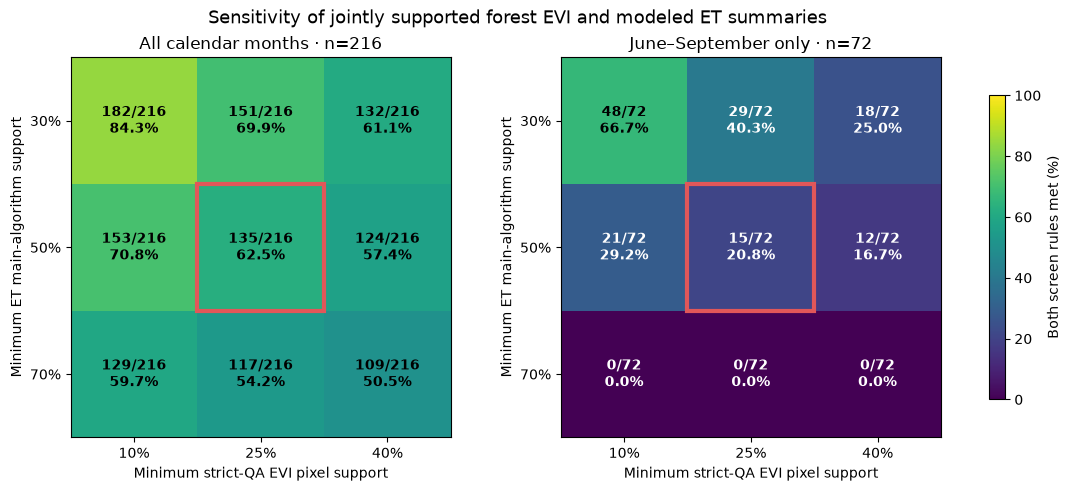

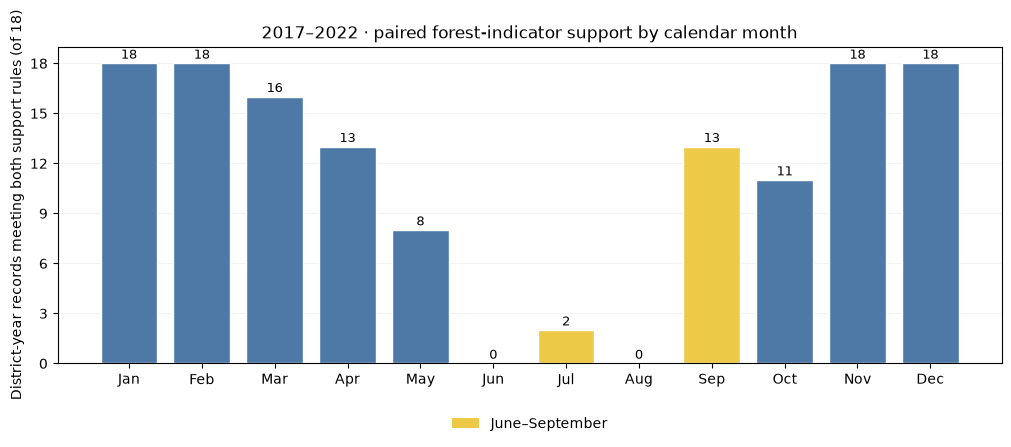

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for ax, (metric, denom, title) in zip(axes, [
    ('all_both_supported_n', 216, 'All calendar months · n=216'),
    ('june_sept_both_supported_n', 72, 'June–September only · n=72')]):
    table = sensitivity.pivot(index='et_main_support_min',
                              columns='evi_support_min', values=metric)
    counts = table.to_numpy()
    im = ax.imshow(counts / denom * 100, cmap='viridis', vmin=0, vmax=100)
    ax.set_xticks(range(3), [f'{int(v*100)}%' for v in EVI_CUTOFFS])
    ax.set_yticks(range(3), [f'{int(v*100)}%' for v in ET_CUTOFFS])
    ax.set_xlabel('Minimum strict-QA EVI pixel support')
    ax.set_ylabel('Minimum ET main-algorithm support')
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            v = int(counts[i, j])
            pct = 100 * v / denom
            ax.text(j, i, f'{v}/{denom}\n{pct:.1f}%', ha='center', va='center',
                    color='white' if pct < 50 else 'black', fontsize=10, weight='bold')
    ax.add_patch(Rectangle((0.5, 0.5), 1, 1, fill=False, edgecolor='#E15759',
                           linewidth=3))
fig.colorbar(im, ax=axes, shrink=0.8, label='Both screen rules met (%)')
fig.suptitle('Sensitivity of jointly supported forest EVI and modeled ET summaries', fontsize=13)
if SAVE_RESULTS:
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / '06_quality_threshold_sensitivity.png', dpi=170,
                bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
colors = ['#EDC948' if m in WET_MONTHS else '#4E79A7'
          for m in monthly_support.calendar_month]
ax.bar(monthly_support.calendar_month, monthly_support.jointly_supported_n,
       color=colors, edgecolor='white', width=0.78)
ax.set_xticks(range(1, 13), [calendar.month_abbr[i] for i in range(1, 13)])
ax.set_ylim(0, 19)
ax.set_yticks([0, 3, 6, 9, 12, 15, 18])
ax.set_ylabel('District-year records meeting both support rules (of 18)')
ax.set_title('2017–2022 · paired forest-indicator support by calendar month')
ax.legend(handles=[Patch(facecolor='#EDC948', label='June–September')],
          loc='upper center', bbox_to_anchor=(0.5, -0.13), frameon=False)
ax.grid(axis='y', alpha=0.15)
ax.set_axisbelow(True)
for month, n in zip(monthly_support.calendar_month, monthly_support.jointly_supported_n):
    ax.text(month, n + 0.28, str(int(n)), ha='center', fontsize=9)
if SAVE_RESULTS:
    fig.savefig(FIGURES / '06_monthly_joint_support.png', dpi=170,
                bbox_inches='tight')
plt.show()


## 6. Export reproducibility metadata and reporting tables

Exports carry `06_` prefixes and can be regenerated from Notebook 04/05.
The manifest records *input SHA256 hashes*, screening definitions and software
versions. No Google credentials, boundary geometry, or private data are exported.


In [6]:
manifest = {
    'study_years': [2017, 2022],
    'districts': districts,
    'scope': 'descriptive product-support threshold sensitivity; no ground validation',
    'wet_season_months': [6, 7, 8, 9],
    'baseline_evi_support': BASELINE_EVI,
    'baseline_et_main_support': BASELINE_ET,
    'evi_support_thresholds': list(EVI_CUTOFFS),
    'et_main_support_thresholds': list(ET_CUTOFFS),
    'source_sha256': {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                      for p in (PANEL_FILE, BASELINE_FILE, DISTRICT_FILE)},
    'software': {'pandas': pd.__version__, 'numpy': np.__version__},
    'figures': ['06_quality_threshold_sensitivity.png', '06_monthly_joint_support.png'],
    'caveat': 'Support screens are exploratory, not confidence bounds or ground accuracy.',
}

if SAVE_RESULTS:
    TABLES.mkdir(parents=True, exist_ok=True)
    sensitivity.to_csv(TABLES / '06_threshold_sensitivity.csv', index=False)
    district_support.to_csv(TABLES / '06_district_evidence_summary.csv', index=False)
    monthly_support.to_csv(TABLES / '06_monthly_joint_support.csv', index=False)
    (TABLES / '06_analysis_manifest.json').write_text(
        json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
    print('Saved 3 CSV tables, 2 PNGs and 1 JSON manifest (prefix 06_).')
else:
    print('Preview only: SAVE_RESULTS=False.')

baseline_line = sensitivity.loc[sensitivity.is_baseline].iloc[0]
print(f'Baseline: {int(baseline_line.all_both_supported_n)}/216 all-year ' 
      f'and {int(baseline_line.june_sept_both_supported_n)}/72 June–September supported.')
print('Inference boundary: no supervised soil-moisture ML or field-validation claim.')


Saved 3 CSV tables, 2 PNGs and 1 JSON manifest (prefix 06_).
Baseline: 135/216 all-year and 15/72 June–September supported.
Inference boundary: no supervised soil-moisture ML or field-validation claim.


## 7. Evidence summary and stopping point

**Supported:** CHIRPS v3 district-wide rainfall seasonality; fixed-2021-MODIS-forest
strict-QA EVI observation support; gap-filled MOD16A2GF ET algorithm provenance;
documented sensitivity of paired observation availability to QA support thresholds.

**Not supported:** measured forest water balance, canopy transpiration, forest-cover
change, a CHT climate trend, soil-moisture prediction performance, ecological causality,
or any product's accuracy against in-situ measurements.

**Important scientific interpretation:** A looser screen makes *more values usable by
definition*, but does not make the values accurate. If wet-season joint availability
changes substantially between scenarios, describe this as **method sensitivity** rather
than claiming one exact data-completeness percentage is a physical truth.

**Next step:** review `docs/research_showcase.md` and `docs/research_limitations_and_future_directions.md`,
check licenses and all captions, and prepare the public research portfolio. Ground
measurements and independent validation are future research, not tasks hidden in a
satellite-only notebook.
